In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
%cd /content
!test -d nanoGPT || git clone https://github.com/karpathy/nanoGPT.git
%cd /content/nanoGPT
!pip -q install tiktoken
!python data/shakespeare_char/prepare.py
!sed -i "s/torch.load(ckpt_path, map_location=device)/torch.load(ckpt_path, map_location=device, weights_only=False)/" sample.py train.py

/content
Cloning into 'nanoGPT'...
remote: Enumerating objects: 689, done.
remote: Total 689 (delta 0), reused 0 (delta 0), pack-reused 689 (from 1)
Receiving objects: 100% (689/689), 981.26 KiB | 8.53 MiB/s, done.
Resolving deltas: 100% (380/380), done.
/content/nanoGPT
length of dataset in characters: 1,115,394
all the unique characters: 
 !$&',-.3:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz
vocab size: 65
train has 1,003,854 tokens
val has 111,540 tokens


In [4]:
helper = '''
import sys, os, runpy, torch
sys.path.insert(0, os.getcwd())
sys.argv = ["train.py"] + sys.argv[1:]
runpy.run_path("train.py", run_name="__main__")
if torch.cuda.is_available():
    print(f"MAX_MEM_MB {torch.cuda.max_memory_allocated() / 1e6:.1f}")
'''
with open('/content/train_with_mem.py', 'w') as f:
    f.write(helper)
print('ok')

ok


In [5]:
import itertools, subprocess, time, re, os, json, statistics

SAVE_ROOT = '/content/drive/MyDrive/nanogpt_experiments'
LOCAL_ROOT = '/content/runs'
os.makedirs(SAVE_ROOT, exist_ok=True)
os.makedirs(LOCAL_ROOT, exist_ok=True)

BLOCK_SIZE = 64
N_LAYER = 4
GRID = list(itertools.product(
    [4, 8],        # n_head
    [128, 256],    # n_embd
    [8, 16],       # batch_size
    [1000, 2000],  # max_iters
    [0.1, 0.2],    # dropout
))
print('Total experiments:', len(GRID))

def run_name(h, e, b, it, dp):
    return f"T{BLOCK_SIZE}_L{N_LAYER}_H{h}_E{e}_B{b}_I{it}_D{dp}"

for idx, (h, e, b, it, dp) in enumerate(GRID, 1):
    name = run_name(h, e, b, it, dp)
    save_dir = os.path.join(SAVE_ROOT, name)
    local_dir = os.path.join(LOCAL_ROOT, name)
    done_file = os.path.join(save_dir, 'result.json')
    if os.path.exists(done_file):
        print(f'[{idx}/32] {name} already done, skipping')
        continue
    os.makedirs(save_dir, exist_ok=True)
    os.makedirs(local_dir, exist_ok=True)

    train_cmd = [
        'python', '/content/train_with_mem.py', 'config/train_shakespeare_char.py',
        f'--out_dir={local_dir}', '--device=cuda', '--compile=False',
        f'--block_size={BLOCK_SIZE}', f'--n_layer={N_LAYER}',
        f'--n_head={h}', f'--n_embd={e}', f'--batch_size={b}',
        f'--max_iters={it}', f'--lr_decay_iters={it}', f'--dropout={dp}',
        '--eval_interval=100', '--eval_iters=50', '--log_interval=10',
        '--always_save_checkpoint=True', '--wandb_log=False',
    ]
    t0 = time.time()
    res = subprocess.run(train_cmd, cwd='/content/nanoGPT', capture_output=True, text=True)
    wall = time.time() - t0
    log = res.stdout + '\n' + res.stderr
    with open(os.path.join(save_dir, 'train_log.txt'), 'w') as f:
        f.write(' '.join(train_cmd) + '\n\n' + log)
    if res.returncode != 0:
        print(f'[{idx}/32] {name} TRAINING FAILED. Last lines of the log:')
        print('\n'.join(log.strip().splitlines()[-15:]))
        continue

    evals = [(int(s), float(tr), float(va)) for s, tr, va in
             re.findall(r'step (\d+): train loss ([\d.]+), val loss ([\d.]+)', log)]
    iter_ms = [float(x) for x in re.findall(r'iter \d+: loss [\d.]+, time ([\d.]+)ms', log)]
    params = re.search(r'number of parameters: ([\d.]+)M', log)
    mem = re.search(r'MAX_MEM_MB ([\d.]+)', log)

    sample_cmd = ['python', 'sample.py', f'--out_dir={local_dir}', '--device=cuda',
                  '--num_samples=2', '--max_new_tokens=300', '--seed=1337']
    s = subprocess.run(sample_cmd, cwd='/content/nanoGPT', capture_output=True, text=True)
    with open(os.path.join(save_dir, 'samples.txt'), 'w') as f:
        f.write(s.stdout + ('\n[stderr]\n' + s.stderr if s.returncode != 0 else ''))

    final_step, final_train, final_val = evals[-1]
    result = dict(
        name=name, block_size=BLOCK_SIZE, n_layer=N_LAYER, n_head=h, n_embd=e,
        batch_size=b, max_iters=it, dropout=dp,
        params_M=float(params.group(1)) if params else None,
        final_train_loss=final_train, final_val_loss=final_val,
        best_val_loss=min(v for _, _, v in evals),
        gap=round(final_val - final_train, 4),
        wall_time_s=round(wall, 1),
        median_ms_per_iter=round(statistics.median(iter_ms[1:]), 2) if len(iter_ms) > 1 else None,
        max_mem_MB=float(mem.group(1)) if mem else None,
        curve=evals,
    )
    with open(done_file, 'w') as f:
        json.dump(result, f, indent=2)
    print(f'[{idx}/32] {name}  train={final_train:.4f}  val={final_val:.4f}  '
          f'gap={result["gap"]:+.4f}  {wall/60:.1f} min')

print('All experiments finished.')

Total experiments: 32
[1/32] T64_L4_H4_E128_B8_I1000_D0.1  train=2.2739  val=2.2690  gap=-0.0049  0.5 min
[2/32] T64_L4_H4_E128_B8_I1000_D0.2  train=2.3382  val=2.3291  gap=-0.0091  0.4 min
[3/32] T64_L4_H4_E128_B8_I2000_D0.1  train=2.0305  val=2.0905  gap=+0.0600  0.8 min
[4/32] T64_L4_H4_E128_B8_I2000_D0.2  train=2.1162  val=2.1565  gap=+0.0403  0.7 min
[5/32] T64_L4_H4_E128_B16_I1000_D0.1  train=2.1031  val=2.1466  gap=+0.0435  0.4 min
[6/32] T64_L4_H4_E128_B16_I1000_D0.2  train=2.2055  val=2.2322  gap=+0.0267  0.4 min
[7/32] T64_L4_H4_E128_B16_I2000_D0.1  train=1.8651  val=1.9670  gap=+0.1019  0.8 min
[8/32] T64_L4_H4_E128_B16_I2000_D0.2  train=1.9946  val=2.0528  gap=+0.0582  0.8 min
[9/32] T64_L4_H4_E256_B8_I1000_D0.1  train=1.9783  val=2.0195  gap=+0.0412  0.4 min
[10/32] T64_L4_H4_E256_B8_I1000_D0.2  train=2.0791  val=2.0985  gap=+0.0194  0.4 min
[11/32] T64_L4_H4_E256_B8_I2000_D0.1  train=1.7364  val=1.8818  gap=+0.1454  0.8 min
[12/32] T64_L4_H4_E256_B8_I2000_D0.2  train=1.85

In [6]:
import glob, json, os
import pandas as pd

SAVE_ROOT = '/content/drive/MyDrive/nanogpt_experiments'
rows = [json.load(open(p)) for p in glob.glob(os.path.join(SAVE_ROOT, '*', 'result.json'))]
df = pd.DataFrame(rows).drop(columns=['curve']).sort_values('final_val_loss').reset_index(drop=True)
df.to_csv(os.path.join(SAVE_ROOT, 'results.csv'), index=False)
print(f'{len(df)} experiments collected. Saved to results.csv')
pd.set_option('display.width', 200)
df

32 experiments collected. Saved to results.csv


,name,block_size,n_layer,n_head,n_embd,batch_size,max_iters,dropout,params_M,final_train_loss,final_val_loss,best_val_loss,gap,wall_time_s,median_ms_per_iter,max_mem_MB
0,T64_L4_H8_E256_B16_I2000_D0.1,64,4,8,256,16,2000,0.1,3.16,1.5843,1.7592,1.7565,0.1749,48.3,13.30,131.7
1,T64_L4_H4_E256_B16_I2000_D0.1,64,4,4,256,16,2000,0.1,3.16,1.5885,1.7683,1.7683,0.1798,47.0,13.50,121.9
2,T64_L4_H4_E256_B16_I2000_D0.2,64,4,4,256,16,2000,0.2,3.16,1.6737,1.8354,1.8354,0.1617,46.9,13.40,121.9
3,T64_L4_H8_E256_B16_I2000_D0.2,64,4,8,256,16,2000,0.2,3.16,1.6731,1.8463,1.8463,0.1732,47.6,13.50,131.7
4,T64_L4_H8_E256_B8_I2000_D0.1,64,4,8,256,8,2000,0.1,3.16,1.7344,1.8726,1.8726,0.1382,46.0,13.00,96.6
5,T64_L4_H4_E256_B8_I2000_D0.1,64,4,4,256,8,2000,0.1,3.16,1.7364,1.8818,1.8818,0.1454,46.6,13.09,91.8
6,T64_L4_H4_E256_B16_I1000_D0.1,64,4,4,256,16,1000,0.1,3.16,1.7820,1.9175,1.9175,0.1355,26.1,13.47,121.9
7,T64_L4_H8_E256_B16_I1000_D0.1,64,4,8,256,16,1000,0.1,3.16,1.7918,1.9237,1.9237,0.1319,26.3,13.31,131.7
8,T64_L4_H8_E256_B8_I2000_D0.2,64,4,8,256,8,2000,0.2,3.16,1.8455,1.9532,1.9532,0.1077,47.1,13.38,96.6
9,T64_L4_H4_E256_B8_I2000_D0.2,64,4,4,256,8,2000,0.2,3.16,1.8501,1.9579,1.9579,0.1078,45.7,13.04,91.8


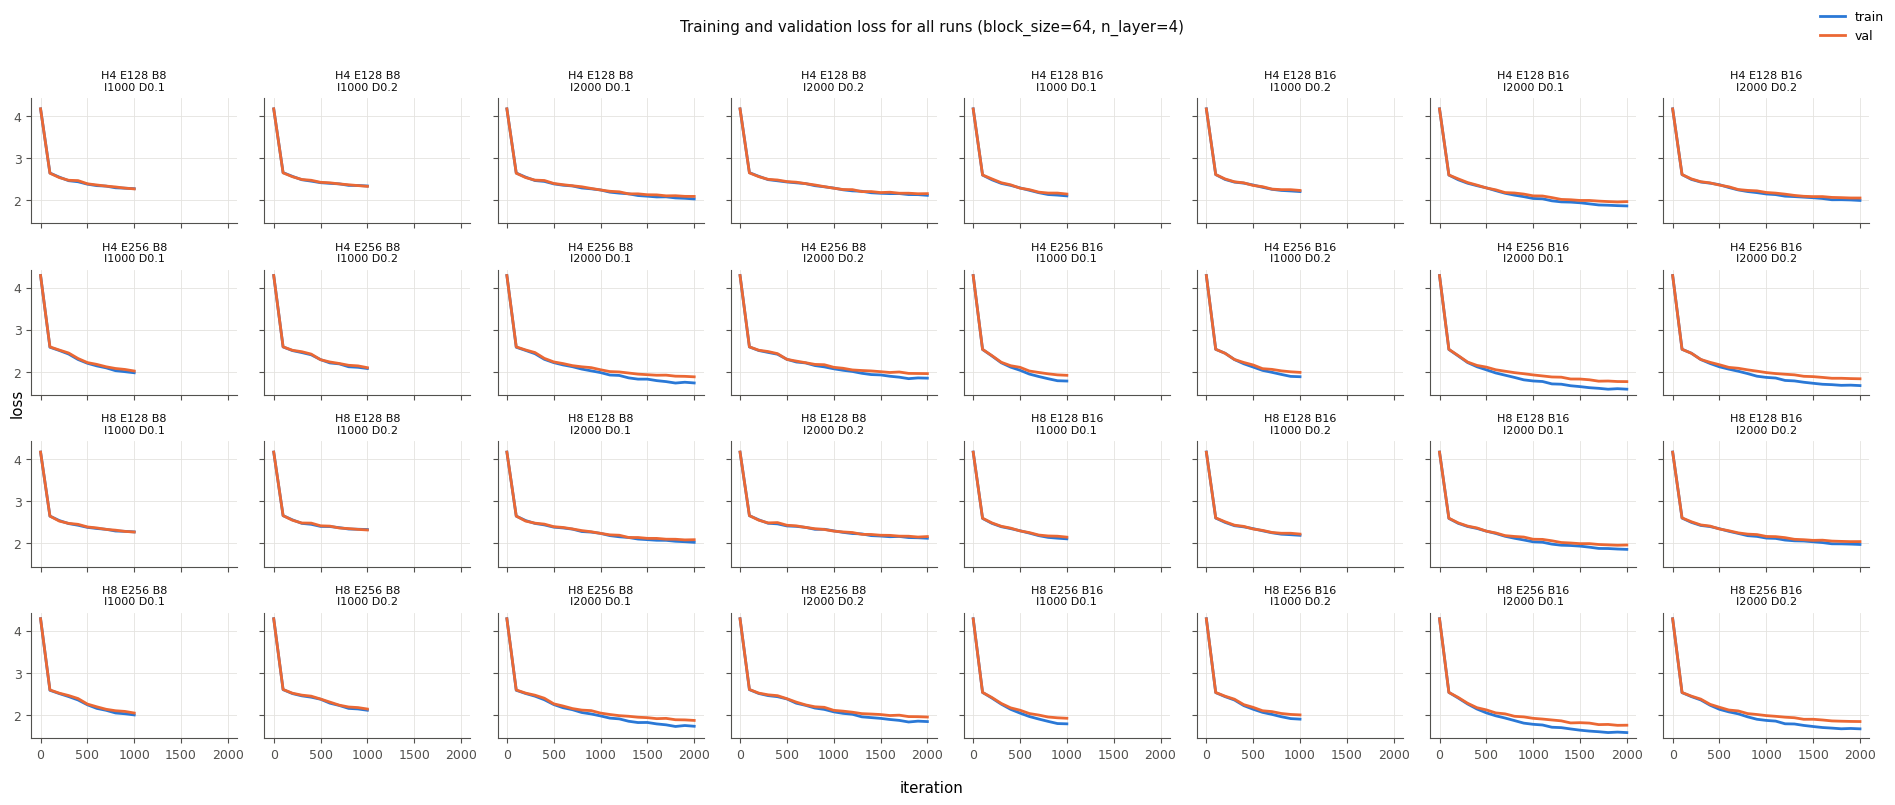

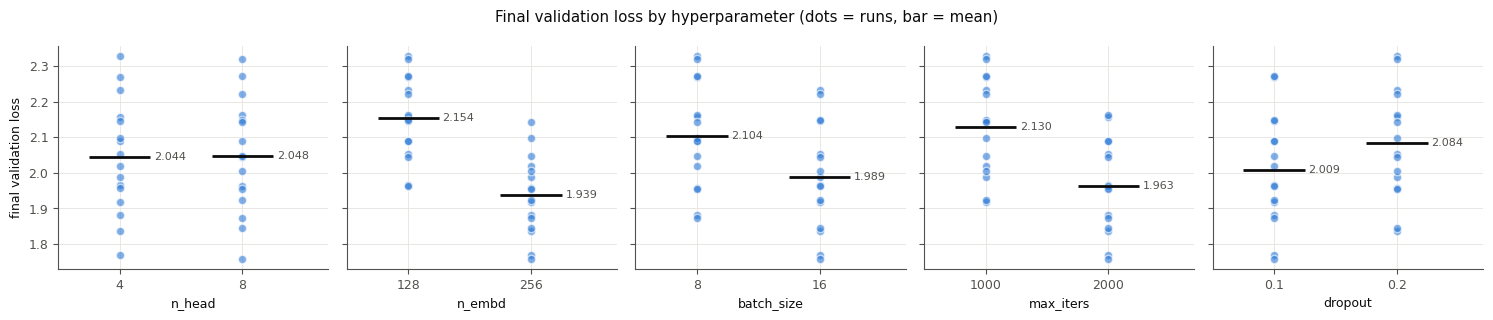

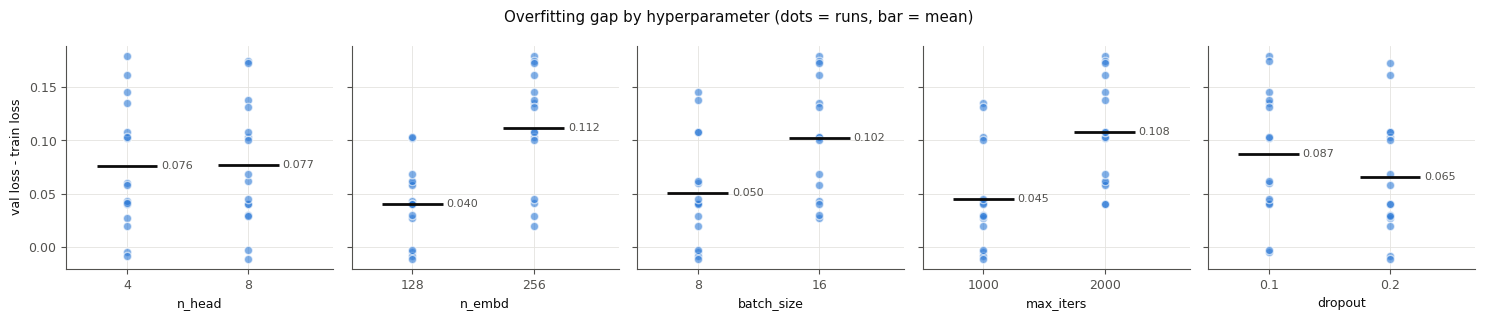

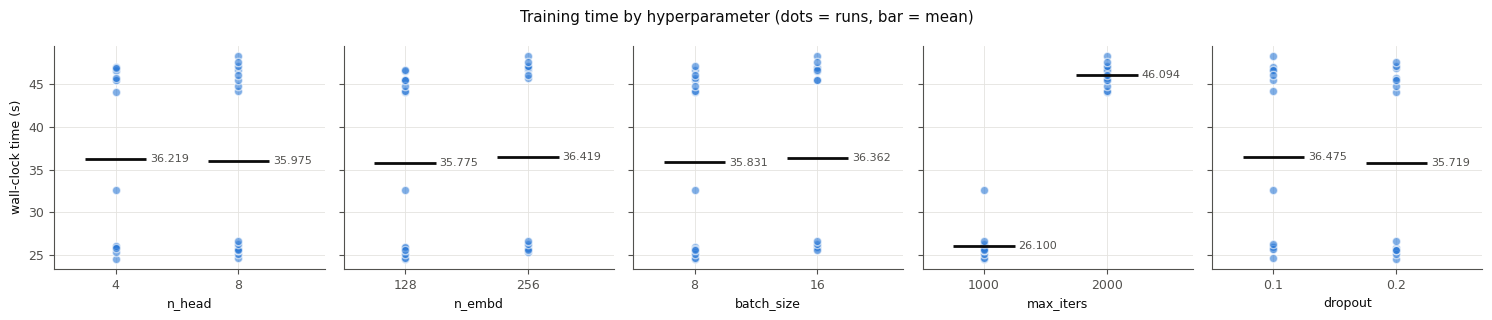

In [7]:
import glob, json, os, math
import matplotlib.pyplot as plt

SAVE_ROOT = '/content/drive/MyDrive/nanogpt_experiments'
runs = sorted([json.load(open(p)) for p in glob.glob(os.path.join(SAVE_ROOT, '*', 'result.json'))],
              key=lambda r: (r['n_head'], r['n_embd'], r['batch_size'], r['max_iters'], r['dropout']))

BLUE, ORANGE = '#2a78d6', '#eb6834'
INK, INK2, GRID_C = '#0b0b0b', '#52514e', '#e4e3df'
plt.rcParams.update({
    'font.size': 9, 'axes.edgecolor': INK2, 'axes.labelcolor': INK, 'xtick.color': INK2,
    'ytick.color': INK2, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRID_C, 'grid.linewidth': 0.6, 'figure.facecolor': 'white',
})

# Figure 1: train/val loss curves for all 32 runs
ncol = 8
nrow = math.ceil(len(runs) / ncol)
fig, axes = plt.subplots(nrow, ncol, figsize=(2.4 * ncol, 2.0 * nrow), sharex=True, sharey=True)
for ax, r in zip(axes.flat, runs):
    steps = [c[0] for c in r['curve']]
    ax.plot(steps, [c[1] for c in r['curve']], color=BLUE, lw=2, label='train')
    ax.plot(steps, [c[2] for c in r['curve']], color=ORANGE, lw=2, label='val')
    ax.set_title(f"H{r['n_head']} E{r['n_embd']} B{r['batch_size']}\nI{r['max_iters']} D{r['dropout']}",
                 fontsize=8, color=INK)
for ax in list(axes.flat)[len(runs):]:
    ax.axis('off')
fig.legend(*axes.flat[0].get_legend_handles_labels(), loc='upper right', frameon=False)
fig.supxlabel('iteration'); fig.supylabel('loss')
fig.suptitle('Training and validation loss for all runs (block_size=64, n_layer=4)', color=INK)
fig.tight_layout(rect=[0, 0, 1, 0.97])
fig.savefig(os.path.join(SAVE_ROOT, 'fig1_loss_curves.png'), dpi=200)
plt.show()

# Figures 2-4: main effect of each hyperparameter (dots = runs, bar = mean)
FACTORS = ['n_head', 'n_embd', 'batch_size', 'max_iters', 'dropout']
def main_effects(metric, ylabel, fname, title):
    fig, axes = plt.subplots(1, len(FACTORS), figsize=(3.0 * len(FACTORS), 3.2), sharey=True)
    for ax, fac in zip(axes, FACTORS):
        levels = sorted({r[fac] for r in runs})
        for i, lv in enumerate(levels):
            vals = [r[metric] for r in runs if r[fac] == lv]
            ax.scatter([i] * len(vals), vals, s=36, color=BLUE, alpha=0.6,
                       edgecolor='white', linewidth=1, zorder=3)
            m = sum(vals) / len(vals)
            ax.hlines(m, i - 0.25, i + 0.25, color=INK, lw=2, zorder=4)
            ax.annotate(f'{m:.3f}', (i + 0.28, m), va='center', fontsize=8, color=INK2)
        ax.set_xticks(range(len(levels)), [str(l) for l in levels])
        ax.set_xlim(-0.5, len(levels) - 0.3)
        ax.set_xlabel(fac)
    axes[0].set_ylabel(ylabel)
    fig.suptitle(title, color=INK)
    fig.tight_layout()
    fig.savefig(os.path.join(SAVE_ROOT, fname), dpi=200)
    plt.show()

main_effects('final_val_loss', 'final validation loss', 'fig2_val_loss_by_factor.png',
             'Final validation loss by hyperparameter (dots = runs, bar = mean)')
main_effects('gap', 'val loss - train loss', 'fig3_gap_by_factor.png',
             'Overfitting gap by hyperparameter (dots = runs, bar = mean)')
main_effects('wall_time_s', 'wall-clock time (s)', 'fig4_time_by_factor.png',
             'Training time by hyperparameter (dots = runs, bar = mean)')

In [8]:
import pandas as pd, os
SAVE_ROOT = '/content/drive/MyDrive/nanogpt_experiments'
df = pd.read_csv(os.path.join(SAVE_ROOT, 'results.csv'))
for label, name in [('BEST (lowest val loss)', df.iloc[0]['name']),
                    ('WORST (highest val loss)', df.iloc[-1]['name'])]:
    print('=' * 80)
    print(label, name)
    print('=' * 80)
    print(open(os.path.join(SAVE_ROOT, name, 'samples.txt')).read()[:1200])

BEST (lowest val loss) T64_L4_H8_E256_B16_I2000_D0.1
Overriding: out_dir = /content/runs/T64_L4_H8_E256_B16_I2000_D0.1
Overriding: device = cuda
Overriding: num_samples = 2
Overriding: max_new_tokens = 300
Overriding: seed = 1337
number of parameters: 3.16M
Loading meta from data/shakespeare_char/meta.pkl...


Clown:
So, whow are is not the dispoke and well.

OSTBRAY:
You hast this heart of her back that a enfriend,
When say will must out he cause her that well
Whice misters, I in lattent drove the death the
would and selfling than the crick him speak;
Or she woy hold night and and a death:
I should that
---------------


KING RICHARD III:
Thee, thou should never now of him the resort,
And nrugh first; if he must with all of which Prience,
They and such still is wards be his gracted
in cour far tear repts offery carence.

PAULINA:
Your shall that hath have mysel-sent,
And said madam strongue in so not us.

ISABELLA:
---------------

WORST (highest val loss) T64_L4_H4_E128_B8_I1000_D0.2

In [9]:
import shutil, os
from google.colab import files

SAVE_ROOT = '/content/drive/MyDrive/nanogpt_experiments'
os.makedirs('/content/for_report', exist_ok=True)
for f in ['results.csv', 'fig1_loss_curves.png', 'fig2_val_loss_by_factor.png',
          'fig3_gap_by_factor.png', 'fig4_time_by_factor.png']:
    shutil.copy(os.path.join(SAVE_ROOT, f), '/content/for_report/')
shutil.make_archive('/content/nanogpt_results', 'zip', '/content/for_report')
files.download('/content/nanogpt_results.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>